# Phase 1: Exploratory Data Analysis (EDA)
## Credit Risk Intelligence: Loan Default Analysis on LendingClub Data

This notebook conducts systematic exploratory data analysis on 50,000 LendingClub loan applications.
We investigate borrower demographics, loan terms, credit bureau metrics, class imbalance, and default correlations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

### 1. Load Raw Dataset

In [2]:
df = pd.read_csv('../data/raw/lending_club_loans.csv')
print(f"Dataset Shape: {df.shape[0]:,} rows, {df.shape[1]} columns")
df.head()

Dataset Shape: 50,000 rows, 25 columns


,loan_amnt,term,int_rate,installment,emp_length,home_ownership,annual_inc,verification_status,purpose,addr_state,...,open_acc,pub_rec,revol_bal,revol_util,total_acc,mort_acc,pub_rec_bankruptcies,tot_cur_bal,total_rev_hi_lim,default
0,10000.0,36 months,13.98,341.68,7 years,MORTGAGE,37800.0,Verified,debt_consolidation,FL,...,9.0,0.0,8218.0,100.2,16.0,0.0,0.0,31967.0,8200.0,1
1,10000.0,36 months,8.49,315.63,10+ years,OWN,36000.0,Not Verified,debt_consolidation,OR,...,7.0,1.0,6395.0,37.2,16.0,0.0,1.0,26744.0,17200.0,0
2,30000.0,60 months,16.55,738.34,4 years,RENT,125000.0,Source Verified,credit_card,NY,...,14.0,1.0,42492.0,76.3,26.0,0.0,0.0,70388.0,55700.0,0
3,25000.0,60 months,17.57,629.01,10+ years,MORTGAGE,83000.0,Not Verified,debt_consolidation,CA,...,22.0,0.0,27434.0,44.4,42.0,0.0,0.0,93465.0,61800.0,0
4,10000.0,36 months,7.12,309.32,10+ years,RENT,60000.0,Not Verified,credit_card,NY,...,6.0,1.0,7132.0,50.2,16.0,0.0,1.0,26540.0,14200.0,1


### 2. Inspect Target Class Distribution (Default vs Fully Paid)

Fully Paid (0): 40,017 (80.03%)
Defaulted  (1): 9,983 (19.97%)
Class Imbalance Ratio: 4.01 : 1


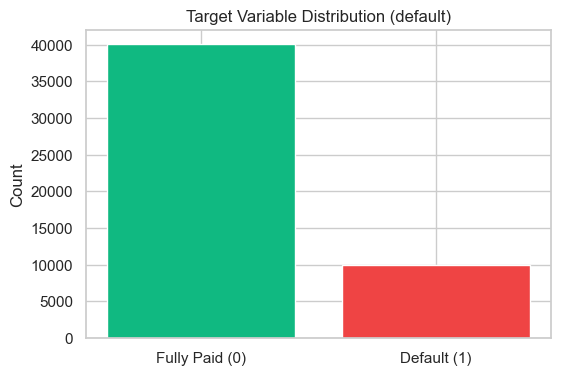

In [3]:
target_counts = df['default'].value_counts()
target_pct = df['default'].value_counts(normalize=True) * 100
print(f"Fully Paid (0): {target_counts[0]:,} ({target_pct[0]:.2f}%)")
print(f"Defaulted  (1): {target_counts[1]:,} ({target_pct[1]:.2f}%)")
print(f"Class Imbalance Ratio: {target_counts[0] / target_counts[1]:.2f} : 1")

plt.figure(figsize=(6, 4))
plt.bar(['Fully Paid (0)', 'Default (1)'], target_counts.values, color=['#10B981', '#EF4444'])
plt.title('Target Variable Distribution (default)')
plt.ylabel('Count')
plt.show()

### 3. Credit Scores & Default Correlation (FICO vs Default Rate)

In [4]:
df['fico_mean'] = (df['fico_range_low'] + df['fico_range_high']) / 2
df['fico_bracket'] = pd.cut(df['fico_mean'], bins=np.arange(640, 860, 20))
fico_analysis = df.groupby('fico_bracket', observed=False)['default'].agg(['count', 'mean'])
fico_analysis['default_rate_%'] = fico_analysis['mean'] * 100
fico_analysis

,count,mean,default_rate_%
fico_bracket,,,
"(640, 660]",0,NaN,NaN
"(660, 680]",17167,0.251820,25.182035
"(680, 700]",13460,0.214859,21.485884
"(700, 720]",9007,0.171200,17.120018
"(720, 740]",5016,0.140949,14.094896
"(740, 760]",2491,0.116018,11.601766
"(760, 780]",1432,0.091480,9.148045
"(780, 800]",828,0.061594,6.159420
"(800, 820]",441,0.072562,7.256236


### 4. Correlation Analysis

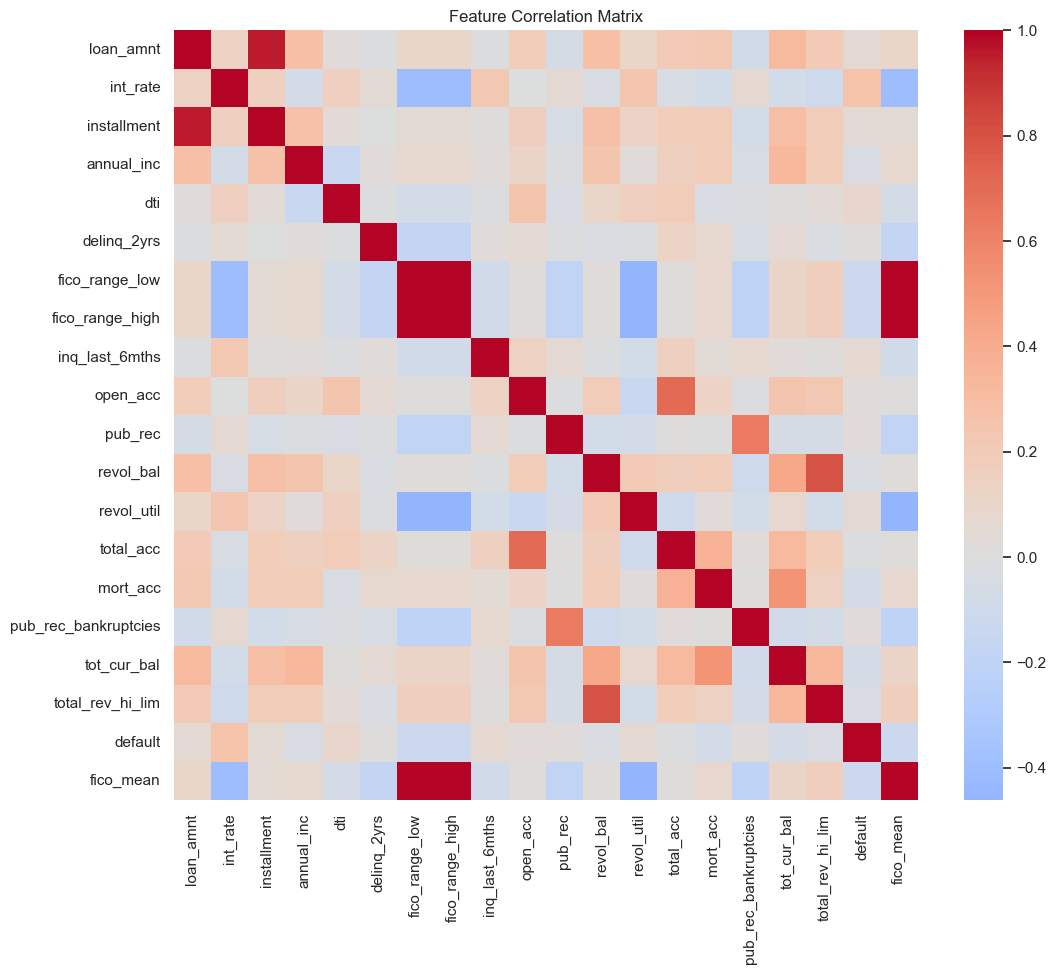

In [5]:
num_cols = df.select_dtypes(include=[np.number]).columns
plt.figure(figsize=(12, 10))
sns.heatmap(df[num_cols].corr(), cmap='coolwarm', center=0, annot=False)
plt.title('Feature Correlation Matrix')
plt.show()